<a href="https://colab.research.google.com/github/SaiNikhil6305/agrilinkk/blob/main/notebooks/AgriLink_quality_benchmark_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Agri-Link · Crop-quality model benchmark (Colab GPU)

Trains and compares **Custom CNN, VGG16, ResNet50, MobileNetV2, EfficientNetB0** on the *Wild Rice Kernel Quality* dataset (CC-BY-4.0), picks the best by validation macro-F1, reports held-out test metrics, and exports `crop_quality_model_final.keras` + `.json` for `ml_backend/models/`.

**Runtime → Change runtime type → GPU** first. Grade mapping: Premium = healthy; Good = low-severity broken/discoloured; Fair = high-severity broken/discoloured, insect-damaged, unhulled.

## 1. Clone the Agri-Link repository and install dependencies

In [1]:
import os
if not os.path.isdir('agri-link'):
    !git clone https://github.com/SaiNikhil6305/agrilinkk.git agri-link
!pip -q install pyarrow huggingface_hub scikit-learn matplotlib
%cd agri-link

Cloning into 'agri-link'...
remote: Enumerating objects: 66, done.
remote: Counting objects: 100% (66/66), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 66 (delta 5), reused 65 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (66/66), 15.62 MiB | 17.98 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/agri-link


## 2. Download all 11 raw shards (16,632 kernels, ~5 GB)

In [2]:
from huggingface_hub import hf_hub_download
import os, shutil
os.makedirs('datasets/raw/wildrice', exist_ok=True)
for i in range(11):
    p = hf_hub_download('Project-AgML/wild_rice_kernel_quality_classification', f'raw/train-{i:05d}-of-00011.parquet', repo_type='dataset')
    shutil.copy(p, f'datasets/raw/wildrice/raw-{i:05d}.parquet')
!ls -la datasets/raw/wildrice

raw/train-00000-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  417MB            

raw/train-00000-of-00011.parquet: downloading bytes:           |  0.00B            

raw/train-00001-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  409MB            

raw/train-00001-of-00011.parquet: downloading bytes:           |  0.00B            

raw/train-00002-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  409MB            

raw/train-00002-of-00011.parquet: downloading bytes:           |  0.00B            

... (13 outputs left out)

raw/train-00009-of-00011.parquet: downloading bytes:           |  0.00B            

raw/train-00010-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  637MB            

raw/train-00010-of-00011.parquet: downloading bytes:           |  0.00B            

total 4938608
drwxr-xr-x 2 root root      4096 Oct 31 07:38 .
drwxr-xr-x 3 root root      4096 Oct 31 07:37 ..
-r--r--r-- 1 root root 416586447 Oct 31 07:37 raw-00000.parquet
-r--r--r-- 1 root root 409174864 Oct 31 07:37 raw-00001.parquet
-r--r--r-- 1 root root 409029344 Oct 31 07:37 raw-00002.parquet
-r--r--r-- 1 root root 424575239 Oct 31 07:37 raw-00003.parquet
-r--r--r-- 1 root root 424849241 Oct 31 07:37 raw-00004.parquet
-r--r--r-- 1 root root 422982752 Oct 31 07:38 raw-00005.parquet
-r--r--r-- 1 root root 416286346 Oct 31 07:38 raw-00006.parquet
-r--r--r-- 1 root root 421246792 Oct 31 07:38 raw-00007.parquet
-r--r--r-- 1 root root 421721102 Oct 31 07:38 raw-00008.parquet
-r--r--r-- 1 root root 653616427 Oct 31 07:38 raw-00009.parquet
-r--r--r-- 1 root root 637012297 Oct 31 07:39 raw-00010.parquet


## 3. Build Premium / Good / Fair folders
Increase the caps for the full run (the CPU run used 300 per healthy/minor class, 150 per severe class → 600 per grade).

In [3]:
!sed -i "s/CAP = {n: (300 if GRADE\[n\] != 'Fair' else 150)/CAP = {n: (1800 if GRADE[n] != 'Fair' else 900)/" datasets/scripts/prepare_wild_rice.py
!rm -rf datasets/quality datasets/demo_quality
!python datasets/scripts/prepare_wild_rice.py datasets/raw/wildrice datasets/quality datasets/demo_quality
!for d in datasets/quality/*; do echo $d $(ls $d | wc -l); done

sed: can't read datasets/scripts/prepare_wild_rice.py: No such file or directory
python3: can't open file '/content/agri-link/datasets/scripts/prepare_wild_rice.py': [Errno 2] No such file or directory
ls: cannot access 'datasets/quality/*': No such file or directory
datasets/quality/* 0


## 4. Benchmark the five models

In [4]:
%cd ml_backend
!python benchmark_models.py --data ../datasets/quality --epochs 40 \
  --dataset-name 'Wild Rice Kernel Quality (Univ. of Manitoba) via AgML' --dataset-license CC-BY-4.0 \
  --label-mapping 'Premium=healthy_large+healthy_medium; Good=broken_low+discoloured_low; Fair=broken_high+discoloured_high+insect_infected+unhulled'

/content/agri-link/ml_backend
I0000 00:00:1793432351.311162    2951 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Traceback (most recent call last):
  File "/content/agri-link/ml_backend/benchmark_models.py", line 221, in <module>
    main()
    ~~~~^^
  File "/content/agri-link/ml_backend/benchmark_models.py", line 99, in main
    classes, items, corrupt = scan(a.data, 0, a.seed)
                              ~~~~^^^^^^^^^^^^^^^^^^^
  File "/content/agri-link/ml_backend/train_classifier.py", line 48, in scan
    classes = sorted(d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d)))
                                ~~~~~~~~~~^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: '../datasets/quality'


# Crop-quality model benchmark

Dataset: Wild Rice Kernel Quality (Univ. of Manitoba) via AgML / Hugging Face Project-AgML/wild_rice_kernel_quality_classification (CC-BY-4.0). Mapping: Premium=healthy_large+healthy_medium; Good=broken_low+discoloured_low; Fair=broken_high+discoloured_high+insect_infected+unhulled

Split: train 1260 / val 270 / test 270 (stratified, duplicates grouped). Selection by validation macro-F1.

| Model | Val macro-F1 | Test accuracy | Test macro-P | Test macro-R | Test macro-F1 | Params | Train s | CPU ms/img |
|---|---|---|---|---|---|---|---|---|
| VGG16 | 0.945 | 0.937 | 0.938 | 0.937 | 0.937 | 14.78M | 411 | 155.1 |
| ResNet50 **(selected)** | 0.974 | 0.937 | 0.938 | 0.937 | 0.937 | 23.85M | 210 | 46.5 |
| MobileNetV2 | 0.933 | 0.933 | 0.933 | 0.933 | 0.933 | 2.42M | 79 | 22.3 |
| EfficientNetB0 | 0.963 | 0.959 | 0.959 | 0.959 | 0.959 | 4.21M | 74 | 16.7 |
| CustomCNN | 0.898 | 0.859 | 0.869 | 0.859 | 0.860 | 0.26M | 697 | 2.8 |


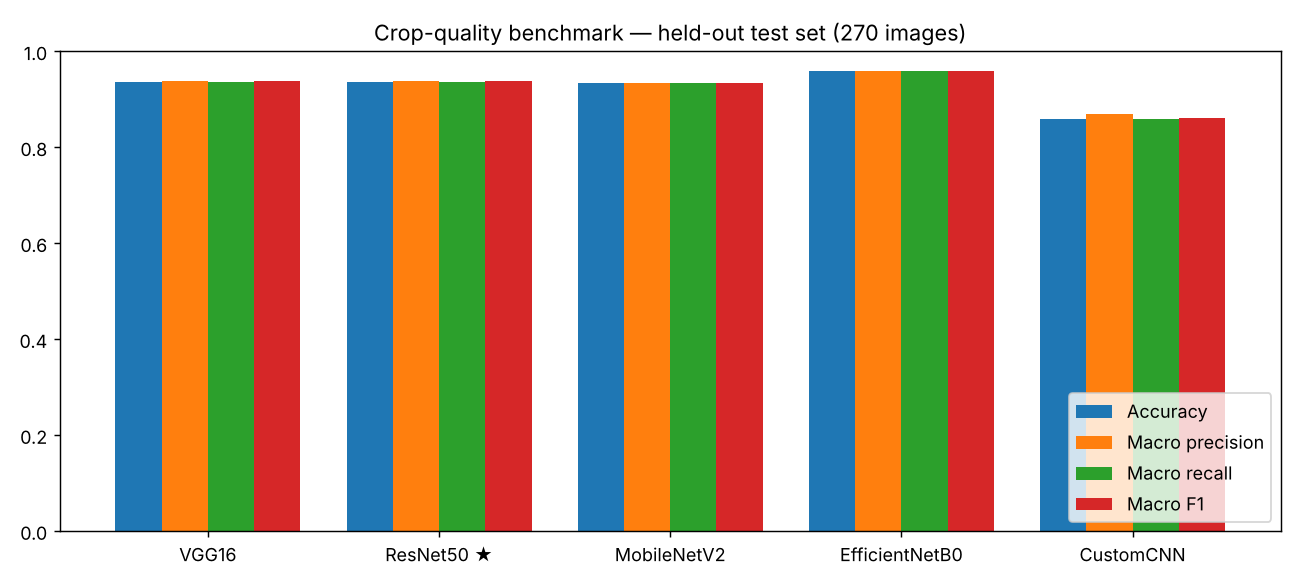

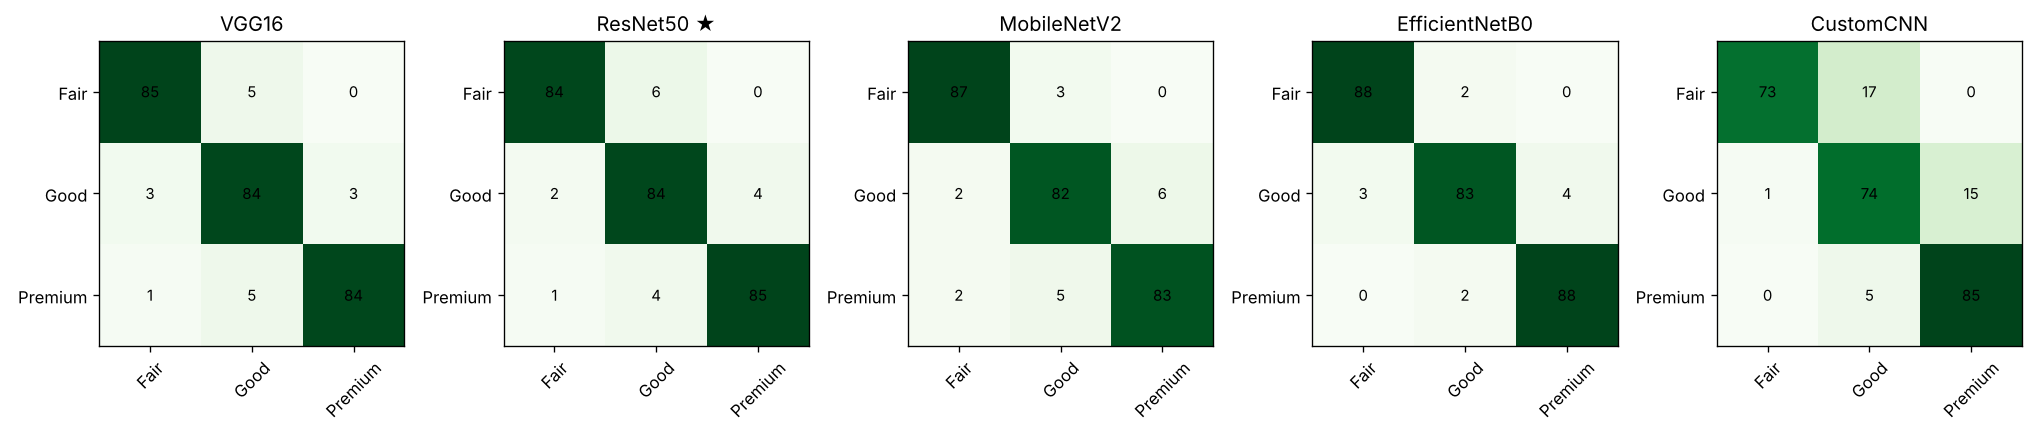

In [5]:
from IPython.display import Image, Markdown, display
display(Markdown(open('models/quality_benchmark/BENCHMARK.md').read()))
display(Image('models/quality_benchmark/benchmark_comparison.png'))
display(Image('models/quality_benchmark/confusion_matrices.png'))

## 5. Check the selected model on never-seen kernels and segregate them into Premium / Good / Bad

In [6]:
!python crop_segregation.py ../datasets/demo_quality | tail -5
!ls ../crop_quality_results/*


0 images checked (0 sent to manual inspection); 0/0 = 0.0% match their true grade
../crop_quality_results/manual_inspection.json


## 6. Download the trained model and attach it to the project
Copy both files into `ml_backend/models/` (replacing the CPU-trained ones) and restart the server.

In [7]:
!cd models && zip -qr ../quality_model.zip crop_quality_model_final.keras crop_quality_model_final.json quality_benchmark
files.download('quality_model.zip')

NameError: name 'files' is not defined

## 7. Fruits & vegetables quality model
FruitNet (7 Indian fruits, Good/Mixed/Bad, CC-BY-4.0), AgML Tomato quality (CC-BY-4.0) and the apple/banana/orange freshness set (MIT). Premium = good/fresh, Good = FruitNet *Mixed*, Fair = bad/rotten. Raise `CAP` for the full run.

In [ ]:
from huggingface_hub import hf_hub_download
import os, shutil
R='datasets/raw'
for sub in ('fruitnet','tomato','freshness'): os.makedirs(f'{R}/{sub}', exist_ok=True)
for i in range(9):
    shutil.copy(hf_hub_download('Project-AgML/FruitNet_quality_classification', f'data/train-{i:05d}-of-00009.parquet', repo_type='dataset'), f'{R}/fruitnet/p{i}.parquet')
shutil.copy(hf_hub_download('Project-AgML/tomato_quality_classification', 'raw/train-00000-of-00001.parquet', repo_type='dataset'), f'{R}/tomato/raw.parquet')
for f in ('train','test'):
    shutil.copy(hf_hub_download('jojogo9/freshness', f'dataset_100/{f}.parquet', repo_type='dataset'), f'{R}/freshness/{f}.parquet')

In [ ]:
%cd /content/agri-link
!rm -rf datasets/produce datasets/demo_produce
!CAP=400 python datasets/scripts/prepare_produce.py datasets/raw datasets/produce datasets/demo_produce
%cd ml_backend
!python benchmark_models.py --data ../datasets/produce --name produce_quality_model --bench-dir produce_benchmark --epochs 40 \
  --supported-crops 'Apple,Banana,Guava,Lemon,Lime,Orange,Pomegranate,Tomato' \
  --dataset-name 'FruitNet + AgML Tomato quality + jojogo9/freshness' --dataset-license 'CC-BY-4.0 / CC-BY-4.0 / MIT' \
  --label-mapping 'Premium=Good/fresh; Good=FruitNet Mixed; Fair=Bad/rotten'
!python crop_segregation.py ../datasets/demo_produce | tail -3

In [ ]:
!cd models && zip -qr ../produce_model.zip produce_quality_model.json produce_quality_model_head.keras produce_benchmark
files.download('produce_model.zip')